# Sales Performance Analysis
## Business goal
Analyze retail sales and profitability to identify strong product categories, regional performance, and monthly trends.

**Dataset:** Sample Superstore (fictional retail data for learning). Download the CSV from the dataset source linked in `../data/README.md` and save it as `Sample - Superstore.csv` inside `data/`.

**Important:** Findings and recommendations should be written only after running the analysis and checking the results.

In [2]:
from google.colab import files
uploaded = files.upload()

Saving Sample - Superstore.csv to Sample - Superstore.csv


In [3]:
import os
print(os.listdir("/content"))

['.config', 'Sample - Superstore.csv', 'sample_data']


## 1. Import libraries
We use pandas for data handling and matplotlib/seaborn for visual analysis.

In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

PROJECT_DIR = Path("/content")
DATA_PATH = PROJECT_DIR / "Sample - Superstore.csv"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "charts"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset exists:", DATA_PATH.exists())
print("Dataset path:", DATA_PATH)

Dataset exists: True
Dataset path: /content/Sample - Superstore.csv


## 2. Load the dataset
If the file isn't found, follow the download instructions in `data/README.md`. Keep the source file unchanged and document any transformations.

In [5]:
import os
from pathlib import Path

print("Files available in Colab:")
for f in os.listdir("/content"):
  print(repr(f))

print("\nExpected file path:")
print(DATA_PATH)

print("\nFile exists:", DATA_PATH.exists())

if DATA_PATH.exists():
  print("File size:", DATA_PATH.stat().st_size, "bytes")

Files available in Colab:
'.config'
'Sample - Superstore.csv'
'outputs'
'sample_data'

Expected file path:
/content/Sample - Superstore.csv

File exists: True
File size: 2287795 bytes


In [6]:
import pandas as pd

try:
  df = pd.read_csv(DATA_PATH, encoding="cp1252", low_memory=False)
  print("CSV loaded successfully!")
  print("Rows:", df.shape[0])
  print("Columns:", df.shape[1])
  display(df.head())

except Exception as e:
  print("Error type:", type(e)._name_)
  print("Error message:", str(e))

CSV loaded successfully!
Rows: 9994
Columns: 21


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 3. Understand the data
Check the shape, column names, data types, missing values, and duplicate rows before cleaning.

In [7]:
# Check dataset size
print("Dataset shape:", df.shape)

# Check column names
print("\nColumn names:")
print(df.columns.tolist())

# Check missing values
print("\nMissing values:")
display(df.isnull().sum())

# Check data types
print("\nData types:")
display(df.dtypes)

# Preview the first five rows
display(df.head())

Dataset shape: (9994, 21)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Missing values:


,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0



Data types:


,0
Row ID,int64
Order ID,object
Order Date,object
Ship Date,object
Ship Mode,object
Customer ID,object
Customer Name,object
Segment,object
Country,object
City,object


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 4. Standardize column names and validate key fields
This notebook expects the standard Superstore fields `Sales`, `Profit`, `Order Date`, `Category`, `Sub-Category`, `Region`, and `Product Name`. Column names are stripped of accidental leading/trailing spaces.

In [8]:
df.columns = df.columns.str.strip()

required = ["Sales", "Profit", "Order Date", "Category", "Sub-Category", "Region", "Product Name"]
missing_required = [col for col in required if col not in df.columns]
if missing_required:
    raise ValueError(
        f"Missing expected columns: {missing_required}. "
        f"Available columns: {df.columns.tolist()}"
    )

df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")
for col in ["Sales", "Profit"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Invalid order dates:", df["Order Date"].isna().sum())
print("Missing sales:", df["Sales"].isna().sum())
print("Missing profit:", df["Profit"].isna().sum())

Invalid order dates: 0
Missing sales: 0
Missing profit: 0


## 5. Clean the data
Keep a separate cleaned dataframe and record what changed. We remove rows missing essential analysis fields; we do not automatically remove negative profit because losses are meaningful business outcomes.

In [9]:
# Create a copy so the original dataset remains unchanged
df_clean = df.copy()

# Remove duplicate rows
print("Duplicate rows:", df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates()

# Convert date columns to datetime
df_clean["Order Date"] = pd.to_datetime(
    df_clean["Order Date"], errors="coerce"
)
df_clean["Ship Date"] = pd.to_datetime(
    df_clean["Ship Date"], errors="coerce"
)

# Convert numerical columns to numeric types
numeric_cols = ["Sales", "Profit", "Quantity", "Discount"]

for col in numeric_cols:
  df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Check missing values after conversion
print("\nDataset shape after removing duplicates:", df_clean.shape)
print("\nMissing values:")
display(df_clean.isnull().sum())

# Display cleaned data
display(df_clean.head())

Duplicate rows: 0

Dataset shape after removing duplicates: (9994, 21)

Missing values:


,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 6. Key performance indicators
Profit margin is calculated as total profit divided by total sales. This is not the same as averaging row-level profit margins.

In [10]:
# Calculate key performance indicators (KPIs)
total_sales = df_clean["Sales"].sum()
total_profit = df_clean["Profit"].sum()
total_orders = df_clean["Order ID"].nunique()
total_customers = df_clean["Customer ID"].nunique()
total_quantity = df_clean["Quantity"].sum()

profit_margin = (
    (total_profit / total_sales) * 100
    if total_sales != 0 else 0
)

print("SALES PERFORMANCE SUMMARY")
print("-" * 35)
print(f"Total Sales:      ${total_sales:,.2f}")
print(f"Total Profit      ${total_profit:,.2f}")
print(f"Total Orders:     {total_orders:,}")
print(f"Total Customers:  {total_customers:,}")
print(f"Units Sold:       {total_quantity:,}")
print(f"Profit margin:    {profit_margin:.2f}%")

SALES PERFORMANCE SUMMARY
-----------------------------------
Total Sales:      $2,297,200.86
Total Profit      $286,397.02
Total Orders:     5,009
Total Customers:  793
Units Sold:       37,873
Profit margin:    12.47%


## 7. Sales and profit by category
Compare revenue and profit together: a high-sales category is not necessarily the most profitable.

In [11]:
# 1. Sales and profit by product category
category_analysis = (
    df_clean.groupby("Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Units_Sold=("Quantity", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
)

print("PERFORMANCE BY CATEGORY")
display(category_analysis.round(2))

# 2. Sales and profit by region
region_analysis = (
    df_clean.groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Orders=("Order ID", "nunique")
    )
    .sort_values("Total_Sales", ascending=False)
)

print("\nPERFORMANCE BY REGION")
display(region_analysis.round(2))

# 3. Sales and profit by sub-category
subcategory_analysis = (
    df_clean.groupby("Sub-Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .sort_values("Total_Profit", ascending=False)
)

print("\nTOP 5 SUB-CATEGORIES BY PROFIT")
display(subcategory_analysis.head(5).round(2))

print("\nBOTTOM 5 SUB-CATEGORIES BY PROFIT")
display(subcategory_analysis.tail(5).round(2))

PERFORMANCE BY CATEGORY


,Total_Sales,Total_Profit,Units_Sold
Category,,,
Technology,836154.03,145454.95,6939
Furniture,741999.80,18451.27,8028
Office Supplies,719047.03,122490.80,22906



PERFORMANCE BY REGION


,Total_Sales,Total_Profit,Orders
Region,,,
West,725457.82,108418.45,1611
East,678781.24,91522.78,1401
Central,501239.89,39706.36,1175
South,391721.90,46749.43,822



TOP 5 SUB-CATEGORIES BY PROFIT


,Total_Sales,Total_Profit
Sub-Category,,
Copiers,149528.03,55617.82
Phones,330007.05,44515.73
Accessories,167380.32,41936.64
Paper,78479.21,34053.57
Binders,203412.73,30221.76



BOTTOM 5 SUB-CATEGORIES BY PROFIT


,Total_Sales,Total_Profit
Sub-Category,,
Machines,189238.63,3384.76
Fasteners,3024.28,949.52
Supplies,46673.54,-1189.10
Bookcases,114880.00,-3472.56
Tables,206965.53,-17725.48


## 8. Regional performance
Rank regions by sales and compare their profit. Investigate any region with strong sales but weak profit.

,Region,Sales,Profit,Profit Margin
3,West,725457.82,108418.45,0.15
1,East,678781.24,91522.78,0.13
0,Central,501239.89,39706.36,0.08
2,South,391721.90,46749.43,0.12


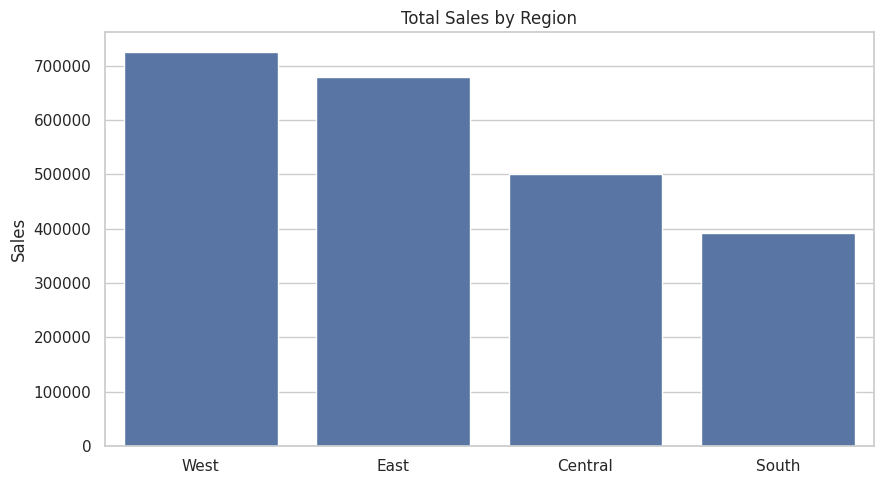

In [12]:
region_summary = (
    df_clean.groupby("Region", as_index=False)
    .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
    .sort_values("Sales", ascending=False)
)
region_summary["Profit Margin"] = region_summary["Profit"] / region_summary["Sales"]
display(region_summary.round(2))

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=region_summary, x="Region", y="Sales", ax=ax)
ax.set_title("Total Sales by Region")
ax.set_ylabel("Sales")
ax.set_xlabel("")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sales_by_region.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Monthly trend
Aggregate sales and profit by month to see trends over time.

In [13]:
# Analyze sales and profit by discount level
discount_analysis = (
    df_clean.groupby("Discount")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Orders=("Order ID", "nunique")
    )
    .sort_index()
)

discount_analysis["Profit_Margin_%"] = (
    discount_analysis["Total_Profit"]
    / discount_analysis["Total_Sales"] * 100
)

print("PERFORMANCE BY DISCOUNT LEVEL")
display(discount_analysis.round(2))

# Investigate the Furniture category
furniture_analysis = (
    df_clean[df_clean["Category"] == "Furniture"]
    .groupby("Sub-Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Average_Discount=("Discount", "mean")
    )
    .sort_values("Total_Profit")
)

print("\nFURNITURE SUB-CATEGORY ANALYSIS")
display(furniture_analysis.round(2))

PERFORMANCE BY DISCOUNT LEVEL


,Total_Sales,Total_Profit,Orders,Profit_Margin_%
Discount,,,,
0.00,1087908.47,320987.60,2644,29.51
0.10,54369.35,9029.18,89,16.61
0.15,27558.52,1418.99,51,5.15
0.20,764594.37,90337.31,2407,11.82
0.30,103226.66,-10369.28,211,-10.05
0.32,14493.46,-2391.14,27,-16.50
0.40,116417.78,-23057.05,185,-19.81
0.45,5484.97,-2493.11,10,-45.45
0.50,58918.54,-20506.43,64,-34.80



FURNITURE SUB-CATEGORY ANALYSIS


,Total_Sales,Total_Profit,Average_Discount
Sub-Category,,,
Tables,206965.53,-17725.48,0.26
Bookcases,114880.00,-3472.56,0.21
Furnishings,91705.16,13059.14,0.14
Chairs,328449.10,26590.17,0.17


,Total_Sales,Total_Profit
Year_Month,,
2014-01,14236.895,2450.1907
2014-02,4519.892,862.3084
2014-03,55691.009,498.7299
2014-04,28295.345,3488.8352
2014-05,23648.287,2738.7096


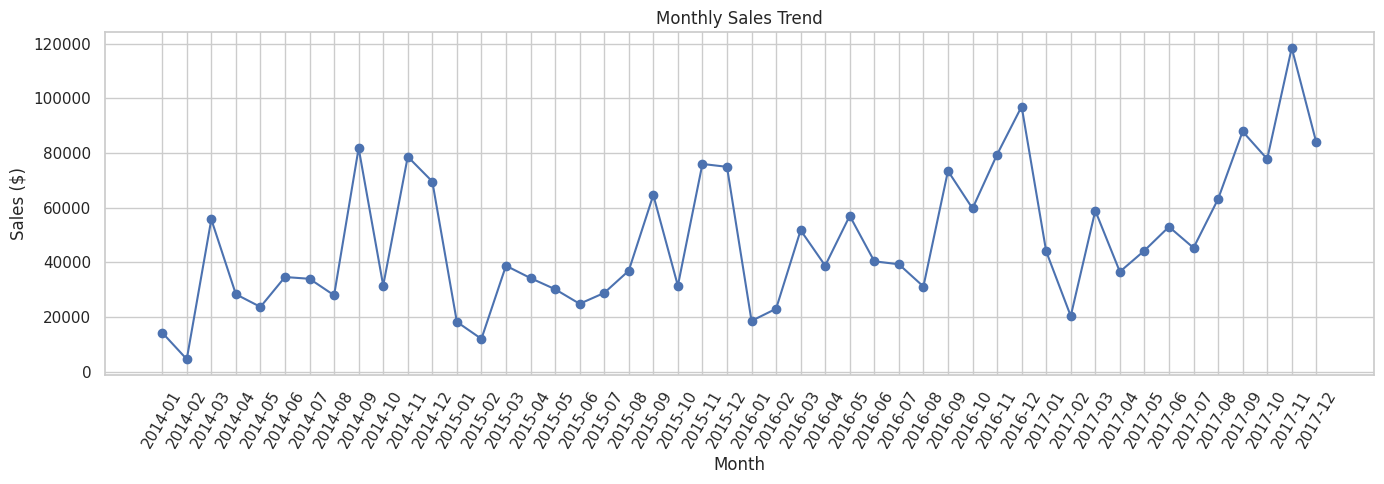

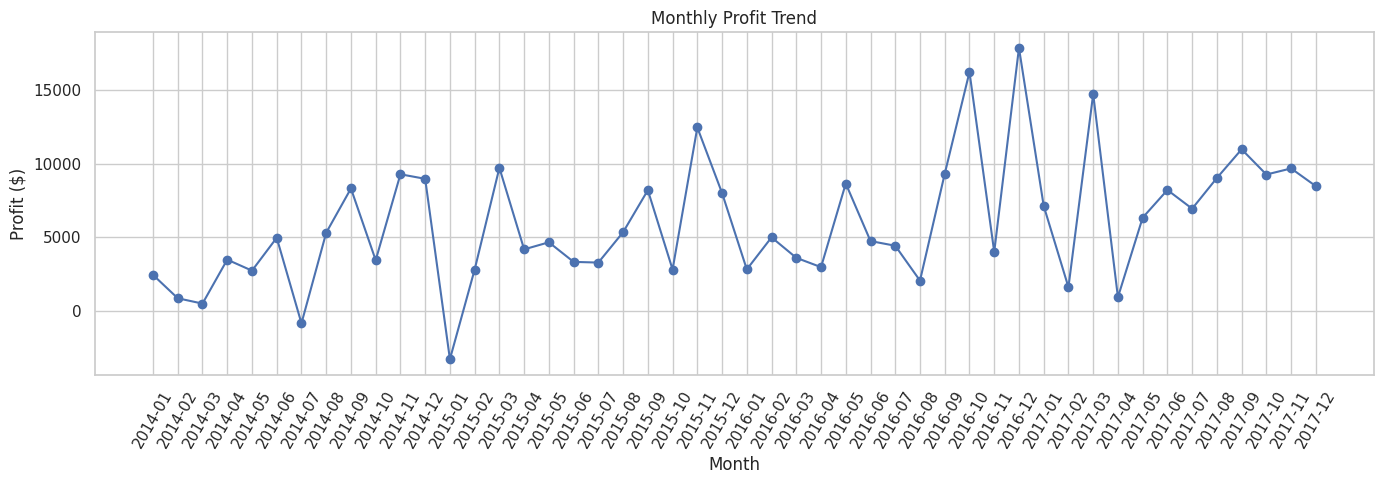

In [14]:
# Create monthly sales and profit summaries
monthly_df = df_clean.dropna(
    subset=["Order Date", "Sales", "Profit"]
).copy()

monthly_df["Year_Month"] = (
    monthly_df["Order Date"].dt.to_period("M").astype(str)
)

monthly_analysis = (
    monthly_df.groupby("Year_Month")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .sort_index()
)

display(monthly_analysis.head())

# Plot monthly sales trend
plt.figure(figsize=(14, 5))
plt.plot(
    monthly_analysis.index,
    monthly_analysis["Total_Sales"],
    marker="o"
)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

# Plot monthly profit trend
plt.figure(figsize=(14, 5))
plt.plot(
    monthly_analysis.index,
    monthly_analysis["Total_Profit"],
    marker="o"
)
plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Profit ($)")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

In [15]:

# Identify the strongest and weakest months
best_sales_month = monthly_analysis["Total_Sales"].idxmax()
worst_sales_month = monthly_analysis["Total_Sales"].idxmin()

best_profit_month = monthly_analysis["Total_Profit"].idxmax()
worst_profit_month = monthly_analysis["Total_Profit"].idxmin()

print("BEST MONTH BY SALES")
print(best_sales_month)
print(round(monthly_analysis.loc[best_sales_month, "Total_Sales"], 2))

print("\nLOWEST MONTH BY SALES")
print(worst_sales_month)
print(round(monthly_analysis.loc[worst_sales_month, "Total_Sales"], 2))

print("\nBEST MONTH BY PROFIT")
print(best_profit_month)
print(round(monthly_analysis.loc[best_profit_month, "Total_Profit"], 2))

print("\nLOWEST MONTH BY PROFIT")
print(worst_profit_month)
print(round(monthly_analysis.loc[worst_profit_month, "Total_Profit"], 2))

print("\nALL MONTHLY RESULTS")
display(monthly_analysis.round(2))


BEST MONTH BY SALES
2017-11
118447.82

LOWEST MONTH BY SALES
2014-02
4519.89

BEST MONTH BY PROFIT
2016-12
17885.31

LOWEST MONTH BY PROFIT
2015-01
-3281.01

ALL MONTHLY RESULTS


,Total_Sales,Total_Profit
Year_Month,,
2014-01,14236.90,2450.19
2014-02,4519.89,862.31
2014-03,55691.01,498.73
2014-04,28295.34,3488.84
2014-05,23648.29,2738.71
2014-06,34595.13,4976.52
2014-07,33946.39,-841.48
2014-08,27909.47,5318.10
2014-09,81777.35,8328.10


## 10. Product-level analysis
Review top products by sales and by profit separately, then identify products with negative total profit.

In [18]:
product_summary = (
    df_clean.groupby("Product Name", as_index=False)
    .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
)
print("Top 10 products by sales")
display(product_summary.nlargest(10, "Sales").round(2))
print("Top 10 products by profit")
display(product_summary.nlargest(10, "Profit").round(2))
print("10 products with lowest total profit")
display(product_summary.nsmallest(10, "Profit").round(2))

Top 10 products by sales


,Product Name,Sales,Profit
404,Canon imageCLASS 2200 Advanced Copier,61599.82,25199.93
650,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.38,7753.04
444,Cisco TelePresence System EX90 Videoconferenci...,22638.48,-1811.08
786,HON 5400 Series Task Chairs for Big and Tall,21870.58,0.00
686,GBC DocuBind TL300 Electric Binding System,19823.48,2233.51
688,GBC Ibimaster 500 Manual ProClick Binding System,19024.50,760.98
805,Hewlett Packard LaserJet 3310 Copier,18839.69,6983.88
787,HP Designjet T520 Inkjet Large Format Printer ...,18374.90,4094.98
683,GBC DocuBind P400 Electric Binding System,17965.07,-1878.17
813,High Speed Automatic Electric Letter Opener,17030.31,-262.00


Top 10 products by profit


,Product Name,Sales,Profit
404,Canon imageCLASS 2200 Advanced Copier,61599.82,25199.93
650,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.38,7753.04
805,Hewlett Packard LaserJet 3310 Copier,18839.69,6983.88
400,Canon PC1060 Personal Laser Copier,11619.83,4570.93
787,HP Designjet T520 Inkjet Large Format Printer ...,18374.90,4094.98
165,Ativa V4110MDD Micro-Cut Shredder,7699.89,3772.95
19,"3D Systems Cube Printer, 2nd Generation, Magenta",14299.89,3717.97
1276,Plantronics Savi W720 Multi-Device Wireless He...,9367.29,3696.28
895,Ibico EPK-21 Electric Binding System,15875.92,3345.28
1840,Zebra ZM400 Thermal Label Printer,6965.70,3343.54


10 products with lowest total profit


,Product Name,Sales,Profit
475,Cubify CubeX 3D Printer Double Head Print,11099.96,-8879.97
985,Lexmark MX611dhe Monochrome Laser Printer,16829.90,-4589.97
476,Cubify CubeX 3D Printer Triple Head Print,7999.98,-3839.99
425,Chromcraft Bull-Nose Wood Oval Conference Tabl...,9917.64,-2876.12
376,Bush Advantage Collection Racetrack Conference...,9544.72,-1934.40
683,GBC DocuBind P400 Electric Binding System,17965.07,-1878.17
444,Cisco TelePresence System EX90 Videoconferenci...,22638.48,-1811.08
1043,Martin Yale Chadless Opener Electric Letter Op...,16656.20,-1299.18
285,Balt Solid Wood Round Tables,6518.75,-1201.06
364,BoxOffice By Design Rectangular and Half-Moon ...,1706.25,-1148.44


## 11. Findings and Recommendations

### 1. Key Findings

- **Overall performance:** Total sales were USD 2,297,200.86, total profit was USD 286,397.02, and the overall profit margin was 12.47%.
- **Top-performing category:** Technology generated the highest sales (USD 836,154.03) and profit (USD 145,454.95).
- **Regional performance:** The West region led with USD 725,457.82 in sales and USD 108,418.45 in profit.
- **Discount impact:** The 30%, 40%, 50%, 60%, 70%, and 80% discount groups recorded negative total profits. This suggests a need to investigate discount policies and product-level profitability.
- **Product performance:** Copiers generated the highest sub-category profit (USD 55,617.82), while Tables recorded the largest loss (USD 17,725.48).
- **Monthly trends:** November 2017 had the highest monthly sales (USD 118,447.82), while December 2016 had the highest monthly profit (USD 17,885.31).

### 2. Business Recommendations

1. Review high-discount transactions to understand their effect on profitability.
2. Investigate the pricing, discount levels, and costs associated with Tables and Bookcases.
3. Study the performance of profitable products such as Copiers, Phones, and Accessories.
4. Investigate the Central region's comparatively low profit margin.
5. Monitor sales, profit, and profit margin together to support better business decisions.

### 3. Conclusion

The analysis shows that high sales do not always translate into high profits. Product category, regional performance, and discount levels are important factors to investigate when improving retail profitability. These findings demonstrate how Python-based data analysis can turn raw sales data into useful business insights.

## 12. Export summary tables
These files can be added to the repository after checking that they contain no restricted data.

In [20]:

from pathlib import Path

OUTPUT_DIR = Path("/content/outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

category_analysis.to_csv(OUTPUT_DIR / "category_analysis.csv")
region_analysis.to_csv(OUTPUT_DIR / "region_analysis.csv")
subcategory_analysis.to_csv(OUTPUT_DIR / "subcategory_analysis.csv")
monthly_analysis.to_csv(OUTPUT_DIR / "monthly_analysis.csv")
discount_analysis.to_csv(OUTPUT_DIR / "discount_analysis.csv")

print("Exported files:")
for file in OUTPUT_DIR.glob("*.csv"):
    print(file.name)


Exported files:
monthly_analysis.csv
category_analysis.csv
discount_analysis.csv
region_analysis.csv
subcategory_analysis.csv


In [21]:

import shutil
from pathlib import Path
from google.colab import files

OUTPUT_DIR = Path("/content/outputs")
ZIP_PATH = "/content/sales_analysis_outputs.zip"

# Create a ZIP containing your outputs
shutil.make_archive(
    "/content/sales_analysis_outputs",
    "zip",
    root_dir=OUTPUT_DIR
)

# Download the ZIP file
files.download(ZIP_PATH)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>